# Gradient descent

Fit a line to generated data by moving its slope and intercept a little at a time. Compare a slow, a useful, and a too-large learning rate. No downloads are needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, SGDRegressor

rng = np.random.default_rng(8)
x = np.linspace(-1, 1, 44)
y = 0.32 * x + 0.48 + rng.normal(0, 0.045, x.size)
X = x.reshape(-1, 1)

## Take steps downhill

Each row of the design matrix gives the two inputs to the line: x for the slope and 1 for the intercept. Average the squared errors and use all rows for every gradient update. Stop a run when its loss is more than 16 times its starting value.

In [2]:
design = np.column_stack((x, np.ones_like(x)))

def walk(rate, steps=100):
    weights = np.zeros(2)
    path = [weights.copy()]
    errors = [np.mean(y ** 2)]
    for _ in range(steps):
        residuals = design @ weights - y
        gradient = 2 / len(y) * design.T @ residuals
        weights -= rate * gradient
        loss = np.mean((design @ weights - y) ** 2)
        if not np.isfinite(loss):
            break
        path.append(weights.copy())
        errors.append(loss)
        if loss > 16 * errors[0]:
            break
    return np.array(path), np.array(errors)

runs = {rate: walk(rate) for rate in [0.001, 0.2, 1.5]}
least_squares = LinearRegression().fit(X, y)
stochastic = SGDRegressor(loss="squared_error", penalty=None,
                          learning_rate="constant", eta0=0.02,
                          max_iter=500, random_state=8).fit(X, y)
print("Batch (slope, intercept):", runs[0.2][0][-1].round(3))
print("Least squares:", least_squares.coef_.round(3), round(least_squares.intercept_, 3))
print("Stochastic:", stochastic.coef_.round(3), stochastic.intercept_.round(3))
assert np.allclose(runs[0.2][0][-1], [least_squares.coef_[0], least_squares.intercept_])

Batch (slope, intercept): [0.317 0.471]
Least squares: [0.317] 0.471
Stochastic: [0.302] [0.47]


## See it

Compare the fitted line, the steps on the loss contours, and the loss at each step. The stochastic estimator above updates from one point at a time; the paths below come from the batch implementation.

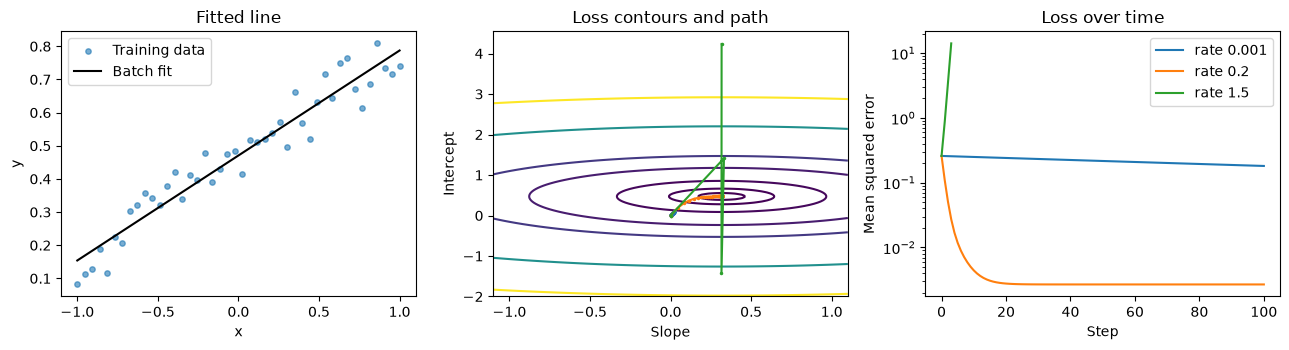

In [3]:
fig, (ax_fit, ax_contour, ax_steps) = plt.subplots(1, 3, figsize=(13, 3.6))
ax_fit.scatter(x, y, s=15, alpha=0.6, label="Training data")
ax_fit.plot(x, design @ runs[0.2][0][-1], color="black", label="Batch fit")
ax_fit.set(xlabel="x", ylabel="y", title="Fitted line")
ax_fit.legend()

slopes, intercepts = np.meshgrid(np.linspace(-1.1, 1.1, 160), np.linspace(-2, 3, 180))
surface = ((slopes[..., None] * x + intercepts[..., None] - y) ** 2).mean(axis=-1)
ax_contour.contour(slopes, intercepts, surface, levels=[0.01, 0.04, 0.15, 0.5, 1, 3, 6])
for rate, (path, errors) in runs.items():
    ax_contour.plot(path[:, 0], path[:, 1], ".-", ms=3, label=f"rate {rate}")
    ax_steps.semilogy(errors, label=f"rate {rate}")
ax_contour.set(xlabel="Slope", ylabel="Intercept", title="Loss contours and path")
ax_steps.set(xlabel="Step", ylabel="Mean squared error", title="Loss over time")
ax_steps.legend()
fig.tight_layout()
plt.show()